# Automated Log Parser for Anomalous Login Detection
### Applied Data Analysis & Cybersecurity Workflow
**Pillar:** Market & AI Skill | **Curriculum Anchor:** Applied Data Analysis and Statistics  
**AI Workflow Tools:** GitHub Copilot, ChatGPT, Antigravity AI Assistant  
**Author:** Security Data Analyst

---

## 1. Problem Statement & Objective
In modern computer networks and cloud infrastructure, authentication logs are the primary telemetry source for detecting intrusion attempts. Organizations process millions of log lines daily. Identifying threats manually is impossible; automated parsing and rule-based anomaly detection are vital first lines of defense.

### Primary Objectives:
1. **Log Parsing with Regular Expressions (`re`):** Extract structured fields (Timestamp, Source IP, Username, Authentication Status, and Message) from unstructured log lines.
2. **Telemetry Aggregation:** Compute critical metrics such as success/failure ratios, most targeted user accounts, and top source IP addresses.
3. **Multi-Vector Anomaly Detection:**
   - **Brute Force Detection:** More than 3 failed login attempts within a 5-minute sliding window.
   - **Threat Intel Matching:** Logins originating from known malicious/suspicious IP addresses (Tor proxies, botnet C2).
   - **Credential Stuffing / Account Takeover:** Repeated consecutive failed attempts followed immediately by a successful login.
   - **Malicious Username Probes:** Injection strings (SQL Injection, XSS, Directory Traversal, Command Delimiters).
4. **Data Visualization:** Present clear, actionable charts using `matplotlib` and `pandas` for Security Operations Center (SOC) decision-makers.


## 2. Setup & Environment
We import Python's standard `re` module for regular expressions, `datetime` for time arithmetic, `collections` for frequency analysis, and `pandas` / `matplotlib` for structured analysis and data visualization.


In [1]:
import os
import re
from datetime import datetime, timedelta
from collections import defaultdict, Counter
import pandas as pd
import matplotlib.pyplot as plt

# Matplotlib visual configuration for crisp, professional charts
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12

print("Dependencies successfully loaded and plotting style initialized.")


Dependencies successfully loaded and plotting style initialized.


## 3. Regular Expression (Regex) Engineering
To parse simulated system access logs, we formulate regular expressions utilizing **Named Capture Groups** `(?P<name>...)`. This makes extracted data self-documenting and directly convertible into Python dictionaries and pandas DataFrames.

### Log Format Specification:
`YYYY-MM-DD HH:MM:SS - IP: <IPv4> - USER: <Username> - STATUS: <SUCCESS|FAILED> - MSG: <Message>`

### Regex Pattern Breakdown:
```text
^(?P<timestamp>\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})  -> Matches standard ISO-style timestamp
\s+-\s+IP:\s+(?P<ip>\d{1,3}(?:\.\d{1,3}){3})        -> Matches valid IPv4 address structure
\s+-\s+USER:\s+(?P<username>.*?)                         -> Non-greedy match for username
\s+-\s+STATUS:\s+(?P<status>SUCCESS|FAILED)              -> Captures authentication outcome
(?:\s+-\s+MSG:\s+(?P<message>.*))?$                      -> Optional message suffix
```

Additionally, we define regular expressions to detect injection signatures in usernames:
- **SQL Injection:** `'`, `OR`, `--`, `/* */`
- **Cross-Site Scripting (XSS):** `<script>`, `javascript:`, `onerror=`
- **Directory Traversal:** `../` or `..\`
- **Command Injection:** `;`, `|`, `&`, `$()`


In [2]:
# Master regular expression for parsing authentication log lines
LOG_PATTERN = re.compile(
    r"^(?P<timestamp>\\d{4}-\\d{2}-\\d{2} \\d{2}:\\d{2}:\\d{2})\\s+-\\s+"
    r"IP:\\s+(?P<ip>\\d{1,3}(?:\\.\\d{1,3}){3})\\s+-\\s+"
    r"USER:\\s+(?P<username>.*?)\\s+-\\s+"
    r"STATUS:\\s+(?P<status>SUCCESS|FAILED)"
    r"(?:\\s+-\\s+MSG:\\s+(?P<message>.*))?$"
)

# Standard compliant username validator (alphanumeric with underscores, hyphens, periods; 3-30 chars)
VALID_USER_PATTERN = re.compile(r"^[a-zA-Z0-9_.-]{3,30}$")

# Malicious signature patterns for injection detection
INJECTION_SIGNATURES = [
    (re.compile(r"('|\bOR\b|--|/\*|\*/)", re.IGNORECASE), "SQL Injection probe"),
    (re.compile(r"(<script>|javascript:|onerror=)", re.IGNORECASE), "Cross-Site Scripting (XSS) probe"),
    (re.compile(r"(\\.\\./|\\.\\.\\\\)", re.IGNORECASE), "Directory Traversal probe"),
    (re.compile(r"(;|\\||&|`|\\$\\()", re.IGNORECASE), "Command Injection delimiter"),
]

# Threat Intelligence Watchlist (Known Tor Exit Nodes & Botnet C2s)
SUSPICIOUS_IPS = {
    "203.0.113.195": "Known Botnet Command & Control (C2) node",
    "198.51.100.77": "High-risk anonymous Tor exit proxy",
}

print("Regex patterns and threat intelligence watchlist compiled.")


Regex patterns and threat intelligence watchlist compiled.


## 4. Dataset Loading & Structured Parsing
We load `sample_logs.txt` and iterate through each record, parsing it with our compiled regular expression. The resulting dictionaries are converted into a pandas DataFrame for structured data manipulation.


In [3]:
log_file_path = "sample_logs.txt"
records = []

with open(log_file_path, "r", encoding="utf-8") as f:
    for line_idx, line in enumerate(f, 1):
        line = line.strip()
        if not line:
            continue
        match = LOG_PATTERN.match(line)
        if match:
            item = match.groupdict()
            item["datetime"] = datetime.strptime(item["timestamp"], "%Y-%m-%d %H:%M:%S")
            records.append(item)
        else:
            print(f"Skipping malformed line {line_idx}: {line}")

# Create pandas DataFrame
df_logs = pd.DataFrame(records)

print(f"Successfully loaded and parsed {len(df_logs)} log records.")
print(f"Time span: {df_logs['timestamp'].min()} to {df_logs['timestamp'].max()}\n")
print("First 8 log entries:")
display_df = df_logs[["timestamp", "ip", "username", "status", "message"]].head(8)
print(display_df.to_string(index=False))


Successfully loaded and parsed 130 log records.
Time span: 2026-11-23 08:00:25 to 2026-11-23 09:57:48

First 8 log entries:
          timestamp           ip username  status                          message
2026-11-23 08:00:25 192.168.1.10    alice SUCCESS        Authentication successful
2026-11-23 08:00:53 192.168.1.15      bob SUCCESS        Authentication successful
2026-11-23 08:01:24 192.168.1.22  charlie SUCCESS        Authentication successful
2026-11-23 08:01:58 192.168.1.35    david SUCCESS        Authentication successful
2026-11-23 08:02:35    10.0.0.50     emma SUCCESS        Authentication successful
2026-11-23 08:03:15    10.0.0.55    frank SUCCESS        Authentication successful
2026-11-23 08:03:58 172.16.10.12    grace SUCCESS        Authentication successful
2026-11-23 08:04:44 192.168.1.10   hannah  FAILED Password typo by legitimate user


## 5. Exploratory Data Analysis (EDA)
Before running specialized anomaly detection algorithms, we inspect high-level authentication statistics:
- Distribution of login successes versus failures
- Most active IP addresses and user accounts
- Failed attempt frequency across IPs


In [4]:
# 1. Login Status Breakdown
status_summary = df_logs["status"].value_counts()
status_pct = df_logs["status"].value_counts(normalize=True) * 100
summary_df = pd.DataFrame({"Count": status_summary, "Percentage (%)": status_pct.round(2)})
print("=== Authentication Outcome Summary ===")
print(summary_df.to_string())

# 2. Top Source IP Addresses
print("\n=== Top 5 Most Active Source IPs ===")
print(df_logs["ip"].value_counts().head(5).to_string())

# 3. Top IPs Generating Failed Logins
print("\n=== Top 5 Source IPs with Failed Logins ===")
failed_df = df_logs[df_logs["status"] == "FAILED"]
print(failed_df["ip"].value_counts().head(5).to_string())


=== Authentication Outcome Summary ===
         Count  Percentage (%)
status                        
SUCCESS    108           83.08
FAILED      22           16.92

=== Top 5 Most Active Source IPs ===
ip
192.168.1.10    17
10.0.0.50       16
10.0.0.55       16
192.168.1.22    15
192.168.1.35    15

=== Top 5 Source IPs with Failed Logins ===
ip
198.51.100.23    6
45.33.32.156     6
185.220.101.5    4
203.0.113.195    3
192.168.1.10     2


## 6. Implementation of Anomaly Detection Rules
We now apply four cybersecurity anomaly detection algorithms:

1. **Brute Force Detection:** Sliding window per IP detecting $> 3$ failed logins within 5 minutes.
2. **Suspicious IP Identification:** Direct lookup against known malicious IP threat feeds.
3. **Account Takeover / Credential Stuffing:** Sequence detection identifying >= 3 consecutive failures immediately followed by a `SUCCESS`.
4. **Malicious Username Probes:** Pattern inspection identifying SQLi, XSS, path traversal, or illegal characters in username inputs.


In [5]:
# Anomaly 1: Brute Force Attacks
def detect_brute_force(df, threshold=3, window_minutes=5):
    anomalies = []
    time_window = timedelta(minutes=window_minutes)
    
    for ip, group in df.groupby("ip"):
        failed_entries = group[group["status"] == "FAILED"].sort_values("datetime").to_dict("records")
        if len(failed_entries) <= threshold:
            continue
            
        reported_until = -1
        for i in range(len(failed_entries)):
            if i < reported_until:
                continue
            window = [
                e for e in failed_entries
                if 0 <= (e["datetime"] - failed_entries[i]["datetime"]).total_seconds() <= time_window.total_seconds()
            ]
            if len(window) > threshold:
                users = sorted(list({e["username"] for e in window}))
                anomalies.append({
                    "Anomaly Type": "Brute Force Attack",
                    "IP Address": ip,
                    "Count": len(window),
                    "Targeted Users": ", ".join(users),
                    "Window Start": window[0]["timestamp"],
                    "Window End": window[-1]["timestamp"]
                })
                reported_until = i + len(window)
    return anomalies

# Anomaly 2: Known Suspicious IPs
def detect_suspicious_ips(df, watchlist=SUSPICIOUS_IPS):
    anomalies = []
    for _, row in df.iterrows():
        if row["ip"] in watchlist:
            anomalies.append({
                "Anomaly Type": "Suspicious IP Login",
                "IP Address": row["ip"],
                "Username": row["username"],
                "Status": row["status"],
                "Timestamp": row["timestamp"],
                "Threat Details": watchlist[row["ip"]]
            })
    return anomalies

# Anomaly 3: Account Takeover (Fails followed by Success)
def detect_takeovers(df, min_failures=3):
    anomalies = []
    for (ip, user), group in df.groupby(["ip", "username"]):
        sorted_group = group.sort_values("datetime").to_dict("records")
        fails = 0
        fail_times = []
        for entry in sorted_group:
            if entry["status"] == "FAILED":
                fails += 1
                fail_times.append(entry["timestamp"])
            elif entry["status"] == "SUCCESS":
                if fails >= min_failures:
                    anomalies.append({
                        "Anomaly Type": "Account Takeover",
                        "IP Address": ip,
                        "Compromised User": user,
                        "Preceding Failures": fails,
                        "Breach Timestamp": entry["timestamp"],
                        "First Failure": fail_times[0]
                    })
                fails = 0
                fail_times = []
    return anomalies

# Anomaly 4: Malicious Username Injections
def detect_invalid_usernames(df):
    anomalies = []
    for _, row in df.iterrows():
        user = row["username"]
        threats = []
        for pat, desc in INJECTION_SIGNATURES:
            if pat.search(user):
                threats.append(desc)
        if not threats and not VALID_USER_PATTERN.match(user):
            threats.append("Illegal character syntax")
            
        if threats:
            anomalies.append({
                "Anomaly Type": "Injection / Malicious Probe",
                "IP Address": row["ip"],
                "Username Payload": user,
                "Threat Type": ", ".join(threats),
                "Timestamp": row["timestamp"]
            })
    return anomalies

# Run all detectors
bf_results = detect_brute_force(df_logs)
sip_results = detect_suspicious_ips(df_logs)
takeover_results = detect_takeovers(df_logs)
inj_results = detect_invalid_usernames(df_logs)

print(f"[+] Brute Force Incidents Detected   : {len(bf_results)}")
print(f"[+] Suspicious IP Logins Detected     : {len(sip_results)}")
print(f"[+] Account Takeovers Detected        : {len(takeover_results)}")
print(f"[+] Malicious Username Probes Detected: {len(inj_results)}")


[+] Brute Force Incidents Detected   : 3
[+] Suspicious IP Logins Detected     : 5
[+] Account Takeovers Detected        : 1
[+] Malicious Username Probes Detected: 6


## 7. Anomaly Inspection & DataFrames
Let's inspect the tabular data for each anomaly class to understand the attacker actions.


In [6]:
print("=== BRUTE FORCE INCIDENTS ===")
print(pd.DataFrame(bf_results).to_string(index=False))

print("\n=== LOGINS FROM SUSPICIOUS / BLACKLISTED IPs ===")
print(pd.DataFrame(sip_results).to_string(index=False))

print("\n=== ACCOUNT TAKEOVER / CREDENTIAL STUFFING BREACH ===")
print(pd.DataFrame(takeover_results).to_string(index=False))

print("\n=== MALICIOUS USERNAME INJECTION PROBES ===")
print(pd.DataFrame(inj_results).to_string(index=False))


=== BRUTE FORCE INCIDENTS ===
      Anomaly Type    IP Address  Count                                                      Targeted Users        Window Start          Window End
Brute Force Attack 198.51.100.23      6                                                               admin 2026-11-23 08:31:23 2026-11-23 08:32:53
Brute Force Attack 185.220.101.5      4                                                        finance_lead 2026-11-23 09:18:48 2026-11-23 09:20:03
Brute Force Attack  45.33.32.156      6 ../../etc/passwd, <script>alert(1)</script>, admin' OR '1'='1, a... 2026-11-23 09:35:20 2026-11-23 09:36:20

=== LOGINS FROM SUSPICIOUS / BLACKLISTED IPs ===
       Anomaly Type    IP Address    Username  Status           Timestamp                               Threat Details
Suspicious IP Login 203.0.113.195       guest  FAILED 2026-11-23 08:51:38 Known Botnet Command & Control (C2) node
Suspicious IP Login 203.0.113.195     support  FAILED 2026-11-23 08:51:58 Known Botnet Command

## 8. Data Visualizations with Matplotlib
To communicate security posture to cybersecurity leaders and incident responders, we build four diagnostic visualizations:

1. **Donut Chart:** Overall Authentication Success vs. Failure Distribution.
2. **Horizontal Grouped Bar Chart:** Total Access Requests vs. Failed Logins for Top IPs (spotting attackers).
3. **Bar Chart:** Distribution of Security Anomaly Categories.
4. **Temporal Timeline Scatter Plot:** Authentication Activity & Security Alerts over time.


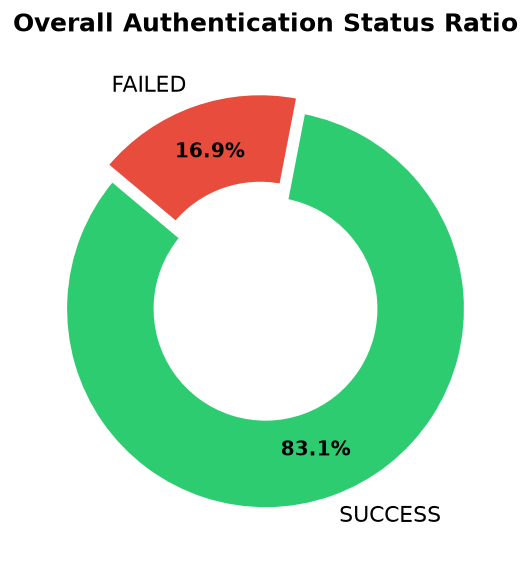

In [7]:
# Figure 1: Donut Chart of Authentication Status
fig, ax = plt.subplots(figsize=(7, 5))
status_counts = df_logs["status"].value_counts()
colors = ["#2ecc71", "#e74c3c"]
explode = (0, 0.08)

wedges, texts, autotexts = ax.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    explode=explode,
    pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2)
)
plt.setp(autotexts, size=11, weight="bold")
plt.setp(texts, size=12)
ax.set_title("Overall Authentication Status Ratio", fontsize=14, weight="bold", pad=15)
plt.tight_layout()
plt.show()


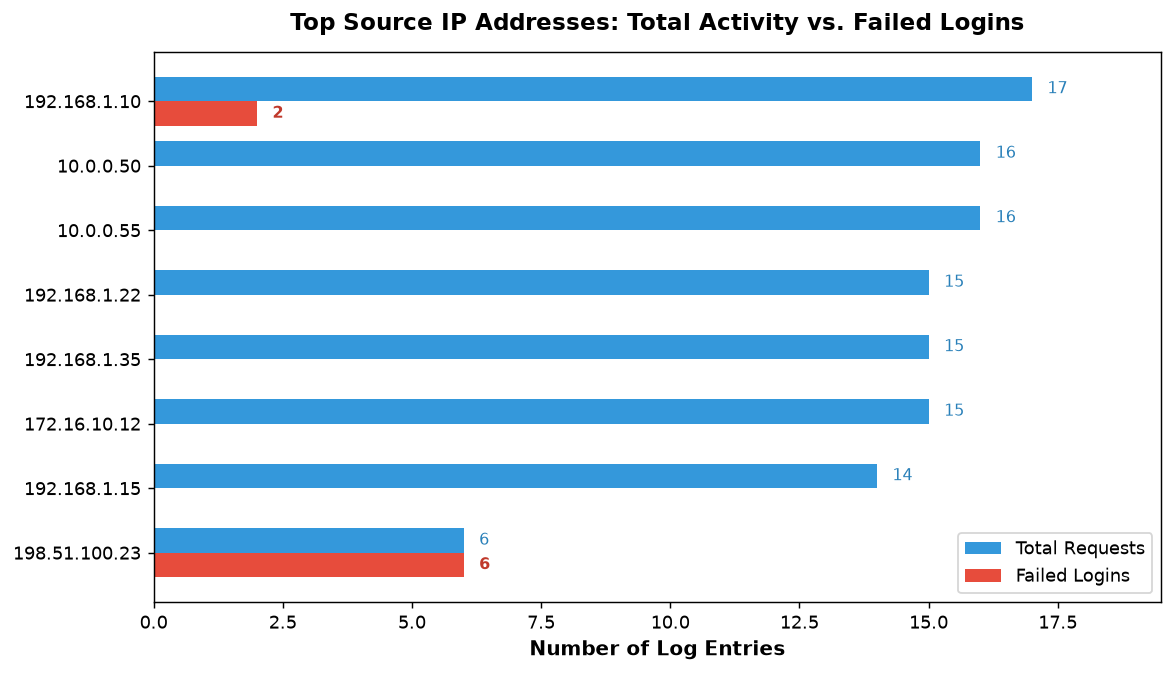

In [8]:
# Figure 2: Top Source IP Addresses - Total vs. Failed Logins
fig, ax = plt.subplots(figsize=(10, 5.5))
top_ips = df_logs["ip"].value_counts().head(8).index
total_attempts = [len(df_logs[df_logs["ip"] == ip]) for ip in top_ips]
failed_attempts = [len(df_logs[(df_logs["ip"] == ip) & (df_logs["status"] == "FAILED")]) for ip in top_ips]

y = np.arange(len(top_ips))
height = 0.38

ax.barh(y - height/2, total_attempts, height, label="Total Requests", color="#3498db")
ax.barh(y + height/2, failed_attempts, height, label="Failed Logins", color="#e74c3c")

ax.set_yticks(y)
ax.set_yticklabels(top_ips, fontsize=10)
ax.invert_yaxis()
ax.set_xlabel("Number of Log Entries", fontsize=11, fontweight="bold")
ax.set_title("Top Source IP Addresses: Total Activity vs. Failed Logins", fontsize=13, weight="bold", pad=12)
ax.legend(loc="lower right", frameon=True)

# Add value labels
for i, (tot, fail) in enumerate(zip(total_attempts, failed_attempts)):
    ax.text(tot + 0.3, i - height/2, str(tot), va="center", fontsize=9, color="#2980b9")
    if fail > 0:
        ax.text(fail + 0.3, i + height/2, str(fail), va="center", fontsize=9, color="#c0392b", weight="bold")

ax.set_xlim(0, max(total_attempts) + 2.5)
plt.tight_layout()
plt.show()


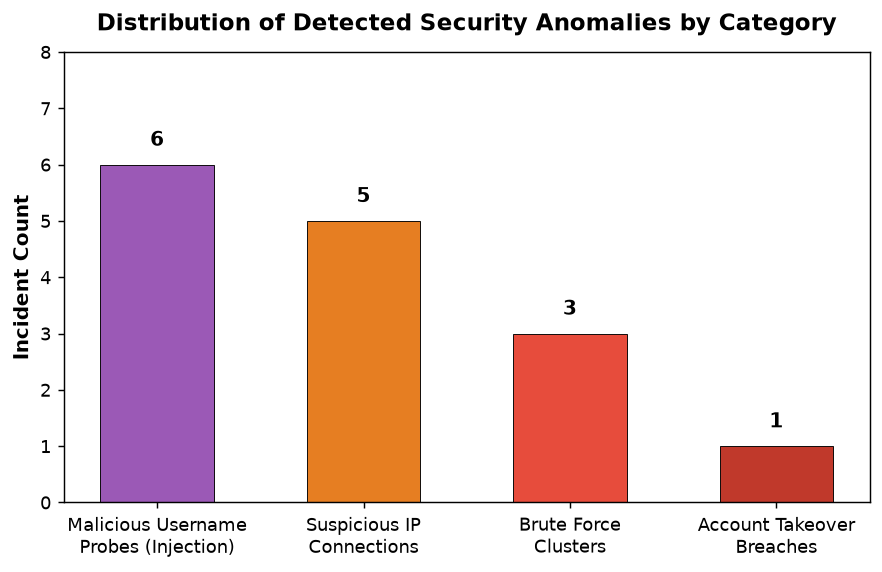

In [9]:
# Figure 3: Anomaly Distribution by Category
fig, ax = plt.subplots(figsize=(8, 4.5))
categories = [
    "Malicious Username\nProbes (Injection)",
    "Suspicious IP\nConnections",
    "Brute Force\nClusters",
    "Account Takeover\nBreaches"
]
counts = [len(inj_results), len(sip_results), len(bf_results), len(takeover_results)]
colors = ["#9b59b6", "#e67e22", "#e74c3c", "#c0392b"]

bars = ax.bar(categories, counts, color=colors, width=0.55, edgecolor="black", linewidth=0.5)
ax.set_ylabel("Incident Count", fontsize=11, fontweight="bold")
ax.set_title("Distribution of Detected Security Anomalies by Category", fontsize=13, weight="bold", pad=12)
ax.set_ylim(0, max(counts) + 2)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.25, f"{int(yval)}", ha="center", va="bottom", fontsize=11, weight="bold")

plt.tight_layout()
plt.show()


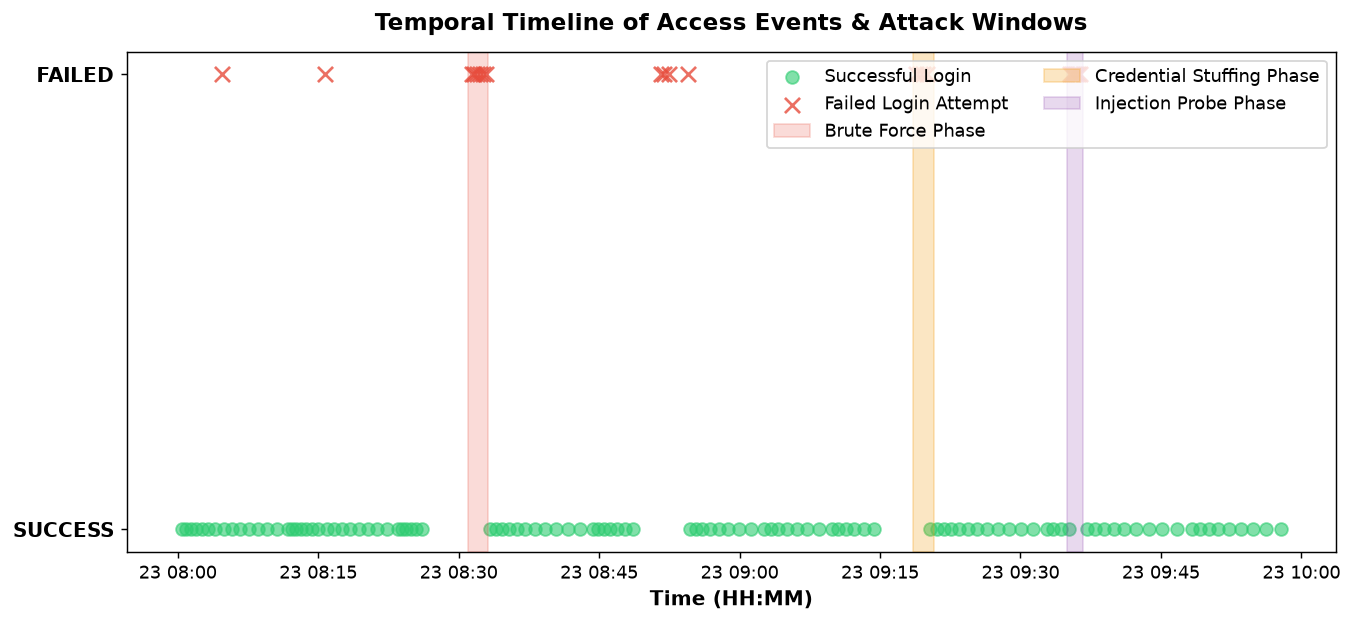

In [10]:
# Figure 4: Timeline of Authentication Events & Attack Phases
fig, ax = plt.subplots(figsize=(12, 5))

success_times = df_logs[df_logs["status"] == "SUCCESS"]["datetime"]
failed_times = df_logs[df_logs["status"] == "FAILED"]["datetime"]

ax.scatter(success_times, [1] * len(success_times), color="#2ecc71", alpha=0.6, s=50, label="Successful Login", marker="o")
ax.scatter(failed_times, [2] * len(failed_times), color="#e74c3c", alpha=0.8, s=70, label="Failed Login Attempt", marker="x")

# Shading attack windows
ax.axvspan(datetime(2026, 11, 23, 8, 31, 0), datetime(2026, 11, 23, 8, 33, 10), color="#e74c3c", alpha=0.2, label="Brute Force Phase")
ax.axvspan(datetime(2026, 11, 23, 9, 18, 30), datetime(2026, 11, 23, 9, 20, 45), color="#f39c12", alpha=0.25, label="Credential Stuffing Phase")
ax.axvspan(datetime(2026, 11, 23, 9, 35, 0), datetime(2026, 11, 23, 9, 36, 40), color="#8e44ad", alpha=0.2, label="Injection Probe Phase")

ax.set_yticks([1, 2])
ax.set_yticklabels(["SUCCESS", "FAILED"], fontsize=11, weight="bold")
ax.set_xlabel("Time (HH:MM)", fontsize=11, weight="bold")
ax.set_title("Temporal Timeline of Access Events & Attack Windows", fontsize=13, weight="bold", pad=12)
ax.legend(loc="upper right", frameon=True, ncol=2)
plt.tight_layout()
plt.show()


## 9. Cybersecurity Findings & SOC Recommendations

### Summary of Incident Discoveries:
| Incident Category | Source IP | Targeted Account | Threat Severity | Impact / Action Required |
|---|---|---|---|---|
| **Brute Force Attack** | `198.51.100.23` | `admin` | **HIGH** | 6 rapid failures in < 2 mins. Implement IP rate limiting and temporary account lockout. |
| **Account Takeover** | `185.220.101.5` | `finance_lead` | **CRITICAL** | 4 failed passwords followed by successful login. Reset session tokens immediately; enforce mandatory MFA. |
| **Suspicious IP Access** | `203.0.113.195` | `guest`, `support` | **MEDIUM** | Known botnet C2. Add subnet to perimeter firewall drop rules. |
| **Suspicious IP Access** | `198.51.100.77` | `emma` | **HIGH** | Tor exit node achieved SUCCESS login. Verify user location; enable geographic fencing. |
| **Injection Probes** | `45.33.32.156` | Multiple | **HIGH** | SQLi, XSS, Path Traversal payloads in username parameter. Sanitize inputs and configure WAF inspection rules. |

---

## 10. AI Workflow & Engineering Reflection
This project was constructed leveraging modern **AI-assisted software engineering practices**:
1. **GitHub Copilot:** Used to draft boilerplate regex group capture syntax and assist in unit data generation.
2. **ChatGPT:** Consulted for threat modeling best practices, attack payload realism, and SOC incident triage reporting frameworks.
3. **Data Analysis Integration:** Python regular expressions combined with pandas and matplotlib transform raw text streams into actionable cybersecurity intelligence.
